In [1]:
# 메타에서 제공해준 광고보고서를 퍼포먼스 마케터 입장에서 효과적인 분석을 위해 파이썬 프로그래밍 언어를 사용
# 파이썬 프로그래밍 언어는 수많은 라이브러리 모듈이 있음
# 광고 보고서는 행과 열 기반의 테이블 형식의 데이터임. 즉, 분석/전처리/시각화 => pandas, plotlt

In [2]:
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
# 소진님 화이팅입니당^0^

In [3]:
df = pd.read_csv("kakao_261012.csv", encoding="utf-8-sig")

df.head()

,캠페인 이름,광고 세트 이름,광고 이름,페이지 이름,연령,성,게재 상태,게재 수준,도달,노출,빈도,기여 설정,결과 유형,결과,지출 금액 (KRW),결과당 비용,시작,종료,링크 클릭,CPC(링크 클릭당 비용),"CPM(1,000회 노출당 비용)",CTR(전체),클릭(전체),CPC(전체),"Meta 계정 1,000개 도달당 비용",고유 링크 클릭,아웃바운드 클릭,고유 아웃바운드 클릭,CTR(링크 클릭률),고유 CTR(링크 클릭률),아웃바운드 CTR(클릭률),고유 아웃바운드 CTR(클릭률),고유 클릭(전체),고유 CTR(전체),고유 링크 클릭당 비용,아웃바운드 클릭당 비용,고유 아웃바운드 클릭당 비용,고유 클릭당 비용(전체),보고 시작,보고 종료,결과(초기)
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2243,2412,1.08,NaN,랜딩 페이지 조회,39.00,16362,419.54,NaN,NaN,54.00,303.00,"6,783.58",2.20,53,308.72,"7,294.69",51.00,54.00,51.00,2.24,2.27,2.24,2.27,52,2.32,320.82,303.00,320.82,314.65,2026-10-01,2026-10-12,NaN
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,카카오톡 선물하기,18-24,male,not_delivering,ad,291,299,1.03,클릭 후 7일 또는 조회 후 1일,랜딩 페이지 조회,3.00,1253,417.67,2026-10-08,2026-10-11,5.00,250.60,"4,190.64",1.67,5,250.60,"4,305.84",5.00,5.00,5.00,1.67,1.72,1.67,1.72,5,1.72,250.60,250.60,250.60,250.60,2026-10-01,2026-10-12,NaN
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,카카오톡 선물하기,18-24,male,not_delivering,ad,210,212,1.01,클릭 후 7일 또는 조회 후 1일,랜딩 페이지 조회,1.00,953,953.00,2026-10-08,2026-10-11,3.00,317.67,"4,495.28",1.42,3,317.67,"4,538.10",3.00,3.00,3.00,1.42,1.43,1.42,1.43,3,1.43,317.67,317.67,317.67,317.67,2026-10-01,2026-10-12,NaN
3,핑퐁 위시리스트,핑퐁위시리스트_영상 _감성자극,영상_감성자극,카카오톡 선물하기,25-34,male,not_delivering,ad,109,111,1.02,클릭 후 7일 또는 조회 후 1일,랜딩 페이지 조회,3.00,914,304.67,2026-10-08,2026-10-11,3.00,304.67,"8,234.23",2.70,3,304.67,"8,385.32",3.00,3.00,3.00,2.70,2.75,2.70,2.75,3,2.75,304.67,304.67,304.67,304.67,2026-10-01,2026-10-12,NaN
4,핑퐁 위시리스트,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,카카오톡 선물하기,25-34,male,not_delivering,ad,88,90,1.02,클릭 후 7일 또는 조회 후 1일,랜딩 페이지 조회,2.00,911,455.50,2026-10-08,2026-10-11,3.00,303.67,"10,122.22",2.22,2,455.50,"10,352.27",2.00,3.00,2.00,3.33,2.27,3.33,2.27,2,2.27,455.50,303.67,455.50,455.50,2026-10-01,2026-10-12,NaN


In [4]:
# 해당 보고서가 어떻게 생겼는지 = 결측자료, 어떤 컬럼으로 구성되었는지, 각 컬럼은 어떤 데이터 타입/평균/최소/최대/이상치 등을 보이고 있는지 확인하기!
# EDA(Exploratory Data Analysis / 탐색적 데이터 분석과정) => 나무가 아닌 숲을 보자!

df.shape # 61행, 41열 데이터 구성

(61, 41)

In [5]:
df.columns #어떤 열로 구성되어 있는가?

Index(['캠페인 이름', '광고 세트 이름', '광고 이름', '페이지 이름', '연령', '성', '게재 상태', '게재 수준',
       '도달', '노출', '빈도', '기여 설정', '결과 유형', '결과', '지출 금액 (KRW)', '결과당 비용', '시작',
       '종료', '링크 클릭', 'CPC(링크 클릭당 비용)', 'CPM(1,000회 노출당 비용)', 'CTR(전체)',
       '클릭(전체)', 'CPC(전체)', 'Meta 계정 1,000개 도달당 비용', '고유 링크 클릭', '아웃바운드 클릭',
       '고유 아웃바운드 클릭', 'CTR(링크 클릭률)', '고유 CTR(링크 클릭률)', '아웃바운드 CTR(클릭률)',
       '고유 아웃바운드 CTR(클릭률)', '고유 클릭(전체)', '고유 CTR(전체)', '고유 링크 클릭당 비용',
       '아웃바운드 클릭당 비용', '고유 아웃바운드 클릭당 비용', '고유 클릭당 비용(전체)', '보고 시작', '보고 종료',
       '결과(초기)'],
      dtype='object')

In [6]:
# 아무리 유용한 데이터가 있어도, 연산 및 집계처리가 불가능하다면 무용지물!
# 결측 데이터가 존재하는지. 만약, 존재한다면 얼만큼 존재하는가?
# 각 컬럼들이 어떤 데이터 타입으로 구성되어 있는가

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61 entries, 0 to 60
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   캠페인 이름                 60 non-null     object 
 1   광고 세트 이름               60 non-null     object 
 2   광고 이름                  60 non-null     object 
 3   페이지 이름                 60 non-null     object 
 4   연령                     60 non-null     object 
 5   성                      60 non-null     object 
 6   게재 상태                  60 non-null     object 
 7   게재 수준                  60 non-null     object 
 8   도달                     61 non-null     int64  
 9   노출                     61 non-null     int64  
 10  빈도                     61 non-null     float64
 11  기여 설정                  60 non-null     object 
 12  결과 유형                  25 non-null     object 
 13  결과                     25 non-null     float64
 14  지출 금액 (KRW)            61 non-null     int64  
 15  결과당 비용  

In [7]:
# 현재 데이터의 요약본

df.describe()

,도달,노출,빈도,결과,지출 금액 (KRW),결과당 비용,링크 클릭,CPC(링크 클릭당 비용),"CPM(1,000회 노출당 비용)",CTR(전체),클릭(전체),CPC(전체),"Meta 계정 1,000개 도달당 비용",고유 링크 클릭,아웃바운드 클릭,고유 아웃바운드 클릭,CTR(링크 클릭률),고유 CTR(링크 클릭률),아웃바운드 CTR(클릭률),고유 아웃바운드 CTR(클릭률),고유 클릭(전체),고유 CTR(전체),고유 링크 클릭당 비용,아웃바운드 클릭당 비용,고유 아웃바운드 클릭당 비용,고유 클릭당 비용(전체),결과(초기)
count,61.00,61.00,61.00,25.00,61.00,25.00,29.00,29.00,61.00,61.00,61.00,29.00,61.00,29.00,29.00,29.00,29.00,29.00,29.00,29.00,61.00,29.00,29.00,29.00,29.00,29.00,0.00
mean,75.57,79.08,1.03,3.12,536.46,302.22,3.72,241.29,"9,325.39",2.57,1.74,241.89,"9,493.56",3.52,3.72,3.52,5.50,5.40,5.50,5.40,1.70,5.48,250.40,241.29,250.40,245.11,NaN
std,287.60,308.93,0.05,7.59,"2,080.27",192.22,9.79,130.40,"8,833.08",4.44,6.80,136.58,"8,834.10",9.24,9.79,9.24,5.64,5.47,5.64,5.47,6.68,5.44,133.14,130.40,133.14,134.10,NaN
min,1.00,1.00,1.00,1.00,2.00,54.71,1.00,23.00,"2,000.00",0.00,0.00,23.00,"2,000.00",1.00,1.00,1.00,0.79,0.79,0.79,0.79,0.00,0.79,23.00,23.00,23.00,23.00,NaN
25%,9.00,10.00,1.00,1.00,70.00,158.00,1.00,139.50,"5,126.21",0.00,0.00,139.50,"5,126.21",1.00,1.00,1.00,2.13,2.22,2.13,2.22,0.00,2.27,147.00,139.50,147.00,147.00,NaN
50%,20.00,21.00,1.00,1.00,176.00,294.00,1.00,256.00,"7,000.00",0.00,0.00,250.60,"7,294.69",1.00,1.00,1.00,3.57,3.45,3.57,3.45,0.00,3.57,256.00,256.00,256.00,250.60,NaN
75%,41.00,42.00,1.03,2.00,376.00,417.67,3.00,304.67,"9,916.67",3.57,1.00,317.67,"9,916.67",2.00,3.00,2.00,7.14,7.69,7.14,7.69,1.00,7.69,320.82,304.67,320.82,317.67,NaN
max,"2,243.00","2,412.00",1.27,39.00,"16,362.00",953.00,54.00,529.00,"52,000.00",25.00,53.00,529.00,"52,000.00",51.00,54.00,51.00,28.57,25.00,28.57,25.00,52.00,25.00,529.00,529.00,529.00,529.00,NaN


In [8]:
df = df[df["캠페인 이름"].notna()].copy() #notna()는, 결측치(누락된 값, NaN/None)가 아닌 정상적인 값을 확인하는 함수

In [9]:
df.describe()

,도달,노출,빈도,결과,지출 금액 (KRW),결과당 비용,링크 클릭,CPC(링크 클릭당 비용),"CPM(1,000회 노출당 비용)",CTR(전체),클릭(전체),CPC(전체),"Meta 계정 1,000개 도달당 비용",고유 링크 클릭,아웃바운드 클릭,고유 아웃바운드 클릭,CTR(링크 클릭률),고유 CTR(링크 클릭률),아웃바운드 CTR(클릭률),고유 아웃바운드 CTR(클릭률),고유 클릭(전체),고유 CTR(전체),고유 링크 클릭당 비용,아웃바운드 클릭당 비용,고유 아웃바운드 클릭당 비용,고유 클릭당 비용(전체),결과(초기)
count,60.00,60.00,60.00,24.00,60.00,24.00,28.00,28.00,60.00,60.00,60.00,28.00,60.00,28.00,28.00,28.00,28.00,28.00,28.00,28.00,60.00,28.00,28.00,28.00,28.00,28.00,0.00
mean,39.45,40.20,1.02,1.62,272.70,297.34,1.93,239.09,"9,367.76",2.58,0.88,239.51,"9,530.21",1.82,1.93,1.82,5.62,5.51,5.62,5.51,0.87,5.59,247.88,239.09,247.88,242.63,NaN
std,56.24,57.18,0.05,1.35,291.95,194.76,1.56,132.24,"8,901.37",4.47,1.34,138.47,"8,903.97",1.42,1.56,1.42,5.71,5.54,5.71,5.54,1.33,5.50,134.88,132.24,134.88,135.88,NaN
min,1.00,1.00,1.00,1.00,2.00,54.71,1.00,23.00,"2,000.00",0.00,0.00,23.00,"2,000.00",1.00,1.00,1.00,0.79,0.79,0.79,0.79,0.00,0.79,23.00,23.00,23.00,23.00,NaN
25%,8.50,9.25,1.00,1.00,67.25,157.00,1.00,139.38,"5,022.69",0.00,0.00,139.38,"5,040.81",1.00,1.00,1.00,2.07,2.14,2.07,2.14,0.00,2.18,145.12,139.38,145.12,145.12,NaN
50%,20.00,21.00,1.00,1.00,175.50,278.00,1.00,253.30,"7,158.73",0.00,0.00,227.30,"7,217.74",1.00,1.00,1.00,3.61,3.51,3.61,3.51,0.00,3.64,253.30,253.30,253.30,227.30,NaN
75%,40.25,40.50,1.02,2.00,358.75,397.29,2.25,307.92,"9,968.06",3.59,1.00,322.75,"10,025.57",2.00,2.25,2.00,7.28,7.69,7.28,7.69,1.00,7.69,322.75,307.92,322.75,322.75,NaN
max,291.00,299.00,1.27,7.00,"1,253.00",953.00,8.00,529.00,"52,000.00",25.00,7.00,529.00,"52,000.00",7.00,8.00,7.00,28.57,25.00,28.57,25.00,7.00,25.00,529.00,529.00,529.00,529.00,NaN


In [10]:
# df.head()
# df.shape
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60 entries, 1 to 60
Data columns (total 41 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   캠페인 이름                 60 non-null     object 
 1   광고 세트 이름               60 non-null     object 
 2   광고 이름                  60 non-null     object 
 3   페이지 이름                 60 non-null     object 
 4   연령                     60 non-null     object 
 5   성                      60 non-null     object 
 6   게재 상태                  60 non-null     object 
 7   게재 수준                  60 non-null     object 
 8   도달                     60 non-null     int64  
 9   노출                     60 non-null     int64  
 10  빈도                     60 non-null     float64
 11  기여 설정                  60 non-null     object 
 12  결과 유형                  24 non-null     object 
 13  결과                     24 non-null     float64
 14  지출 금액 (KRW)            60 non-null     int64  
 15  결과당 비용       

In [11]:
# 광고보고서 세부적으로 분석
# 아래 필요한 12개의 컬럼만 찾아올 계획

columns = [
    "캠페인 이름",
    "광고 세트 이름",
    "광고 이름",
    "연령",
    "성",
    "도달",
    "노출",
    "빈도",
    "결과",
    "지출 금액 (KRW)",
    "링크 클릭",
    "클릭(전체)",
]

ads = df[columns].copy()

ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체)
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3
3,핑퐁 위시리스트,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3
4,핑퐁 위시리스트,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,NaN,903,2.00,2


In [12]:
ads.info()

<class 'pandas.core.frame.DataFrame'>
Index: 60 entries, 1 to 60
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   캠페인 이름       60 non-null     object 
 1   광고 세트 이름     60 non-null     object 
 2   광고 이름        60 non-null     object 
 3   연령           60 non-null     object 
 4   성            60 non-null     object 
 5   도달           60 non-null     int64  
 6   노출           60 non-null     int64  
 7   빈도           60 non-null     float64
 8   결과           24 non-null     float64
 9   지출 금액 (KRW)  60 non-null     int64  
 10  링크 클릭        28 non-null     float64
 11  클릭(전체)       60 non-null     int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 6.1+ KB


In [13]:
ads["결과"] = ads["결과"].fillna(0)
ads["링크 클릭"] = ads["링크 클릭"].fillna(0)

In [14]:
ads.isna().sum() # 결측치 합계를 확인하기 위한 코드

캠페인 이름         0
광고 세트 이름       0
광고 이름          0
연령             0
성              0
도달             0
노출             0
빈도             0
결과             0
지출 금액 (KRW)    0
링크 클릭          0
클릭(전체)         0
dtype: int64

In [15]:
ads["광고 이름"].head() # 2개의 열을 신규 추가 가능

1    이미지_감성자극
2    이미지_혜택강조
3     영상_감성자극
4     영상_혜택강조
5    이미지_혜택강조
Name: 광고 이름, dtype: object

In [16]:
ads["광고 유형"] = ads["광고 이름"].str.split("_").str[0]
ads["메세지 유형"] = ads["광고 이름"].str.split("_").str[1]

In [17]:
ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [18]:
spend = ads["지출 금액 (KRW)"].sum() # 총 광고비
impressions = ads["노출"].sum() # 총 노출
arrival = ads["도달"].sum() # 총 도달
clicks = ads["링크 클릭"].sum() # 총 링크 클릭
landing = ads["결과"].sum() # 총 랜딩 페이지 조회

ctr = clicks / impressions * 100
cpc = spend / clicks
cpm = spend / impressions * 1000
cost_per_landing = spend / landing # 랜딩 조회당 비용

print("총 광고비:", f"{spend:,}원")
print("총 노출:", f"{impressions:,}회")
print("총 도달:", f"{arrival:,}회")
print("링크 클릭:", f"{clicks:,.0f}회")
print("랜딩 페이지 조회:", f"{landing:,.0f}회")
print("CTR:", f"{ctr:,.2f}%")
print("CPC:", f"{cpc:,.2f}원")
print("CPM:", f"{cpm:,.2f}원")
print("랜딩 조회당 비용:", f"{cost_per_landing:,.2f}원")

총 광고비: 16,362원
총 노출: 2,412회
총 도달: 2,367회
링크 클릭: 54회
랜딩 페이지 조회: 39회
CTR: 2.24%
CPC: 303.00원
CPM: 6,783.58원
랜딩 조회당 비용: 419.54원


In [19]:
funnel = pd.DataFrame({
    "단계": ["노출", "도달", "링크 클릭", "랜딩 페이지 조회"],
    "사용자 행동 수": [impressions, arrival, clicks, landing]
                 })

funnel

,단계,사용자 행동 수
0,노출,"2,412.00"
1,도달,"2,367.00"
2,링크 클릭,54.00
3,랜딩 페이지 조회,39.00


In [20]:
import plotly.express as px

fig = px.funnel(
    funnel,
    x="사용자 행동 수",
    y="단계",
    title="Meta 광고 유입 퍼널"
)

fig.update_traces(texttemplate="%{x:,}회") 
# % = 입력 자료형, 외부의 값을 가져와서 해당 값에 어떤 문자열 처리를 하고자 할 때, 앞에 %라는 입력 자료형을 사용

fig.show()

In [21]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? Yes
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까?

ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [22]:
ads["캠페인 이름"] = ads["캠페인 이름"].replace({"핑퐁 위시리스트":"핑퐁 위시리스트 - 영상"})

In [23]:
ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [24]:
campaign = ads.groupby("캠페인 이름", as_index=False).agg({
    "지출 금액 (KRW)":"sum",
    "노출":"sum",
    "링크 클릭":"sum",
    "결과":"sum",
})

campaign["CTR"] = campaign["링크 클릭"] / campaign["노출"] * 100
campaign["CPC"] = campaign["지출 금액 (KRW)"] / campaign["링크 클릭"]
campaign

# 16,362원
# 영상 : 8,180원
# 이미지 : 8,182원
# **메타 광고 집행 시, 카드 정보 입력을 했을 경우, 내가 광고 집행 시 세팅한 금액 모두 태우고 추가로 세금을 떼지만,
# **충전으로 했을 경우, 광고 집행 시 세팅한 금액 안에 세금이 포함됨

,캠페인 이름,지출 금액 (KRW),노출,링크 클릭,결과,CTR,CPC
0,핑퐁 위시리스트 - 영상,8180,875,30.00,24.00,3.43,272.67
1,핑퐁 위시리스트 - 이미지,8182,1537,24.00,15.00,1.56,340.92


In [25]:
fig = px.bar(
    campaign,
    x="캠페인 이름",
    y="지출 금액 (KRW)",
    color="캠페인 이름",
    text_auto=True,
    title="캠페인별 광고비 비교"
)

fig.update_traces(texttemplate="%{y:,.0f}원")
fig.show()

In [26]:
fig = px.bar(
    campaign,
    x="캠페인 이름",
    y="CTR",
    color="캠페인 이름",
    text_auto=".2f",
    title="캠페인별 CTR 비교"
)

fig.update_traces(texttemplate="%{y:,.2f}%")
fig.show()

#CTR : 클릭률

In [27]:
# ads_type = ads.groupby("광고 유형", as_index=False).agg({
#     "지출 금액 (KRW)":"sum",
#     "노출":"sum",
#     "링크 클릭":"sum",
#     "결과":"sum",
# })

ads_type = ads.groupby("광고 유형", as_index=False)[
    ["지출 금액 (KRW)", "노출", "링크 클릭", "결과"]
].sum()

ads_type["CTR"] = ads_type["링크 클릭"] / ads_type["노출"] * 100
ads_type["CPC"] = ads_type["지출 금액 (KRW)"] / ads_type["링크 클릭"]
ads_type

,광고 유형,지출 금액 (KRW),노출,링크 클릭,결과,CTR,CPC
0,영상,8180,875,30.00,24.00,3.43,272.67
1,이미지,8182,1537,24.00,15.00,1.56,340.92


In [28]:
fig = px.bar(
    ads_type,
    x="광고 유형",
    y="CTR",
    color="광고 유형",
    text_auto=".2f",
    title="이미지 vs 영상 CTR 비교"
)

fig.update_traces(texttemplate="%{y:,.2f}%")
fig.show()

In [29]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? Yes
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? 영상
# 3) 영상이 이미지 클릭을 더 많이 유도했다는 것은 인정 -> 그러나 영상과 이미지 유형에는 혜택과 감성으로 나누어져 있었다.
# => 만약, 영상(혜택 90% / 감성 10%), 이미지(혜택 50% / 감성 50%)였다면?

In [30]:
creative = ads.groupby("광고 이름", as_index=False)[
    ["지출 금액 (KRW)", "노출", "링크 클릭", "결과"]
].sum()

creative["CTR"] = creative["링크 클릭"] / creative["노출"] * 100
creative["CPC"] = creative["지출 금액 (KRW)"] / creative["링크 클릭"]
creative["LPV"] = creative["지출 금액 (KRW)"] / creative["결과"]

# Landing Page View 비용

creative

# 혜택을 강조하는 메세지는 영상이 유리했으나, 감성을 자극하는 메세지는 영상보다 이미지가 더 유리했다!
# 직관적인 혜택을 제공할 때는, 짧고 굵은 영상 메세지를 전달하는 것이 맞고, 감성을 터치하고자 할 때는 이미지 방식을 선택하는 것이 맞다!

,광고 이름,지출 금액 (KRW),노출,링크 클릭,결과,CTR,CPC,LPV
0,영상_감성자극,3998,450,12.00,9.00,2.67,333.17,444.22
1,영상_혜택강조,4182,425,18.00,15.00,4.24,232.33,278.80
2,이미지_감성자극,4110,796,15.00,10.00,1.88,274.00,411.00
3,이미지_혜택강조,4072,741,9.00,5.00,1.21,452.44,814.40


In [31]:
fig = px.bar(
    creative,
    x="광고 이름",
    y="CTR",
    color="광고 이름",
    text_auto=".2f",
    title="광고 소재별 CTR 비교"
)

fig.update_traces(texttemplate="%{y:,.2f}%")

fig.update_layout(
    xaxis_title="광고 소재",
    yaxis_title="CTR (%)"
)

fig.show()

# 데이터는 단일 요소만 가지고 비즈니스 의사결정을 하면 절대 안 됨!

In [32]:
fig = px.bar(
    creative,
    x="광고 이름",
    y="CPC",
    color="광고 이름",
    text_auto=".2f",
    title="광고 소재별 CPC 비교"
)

fig.update_traces(texttemplate="%{y:,.0f}원")

fig.update_layout(
    xaxis_title="광고 소재",
    yaxis_title="CPC (원)"
)

fig.show()

# 데이터는 단일 요소만 가지고 비즈니스 의사결정을 하면 절대 안 됨!

In [33]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? Yes
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? 영상
# 3) 컨텐츠 마케팅 전략 수립 : 영상 - 혜택 강조, 이미지 - 감성 자극
# 4) 영상 및 이미지 라는 소재 유형을 다 떠나서 혜택, 감성 둘 중에는 어떤 것이 효과적이었을까?

In [34]:
message = ads.groupby("메세지 유형", as_index=False)[
    ["지출 금액 (KRW)", "노출", "링크 클릭", "결과"]
].sum()

message["CTR"] = message["링크 클릭"] / message["노출"] * 100
message["CPC"] = message["지출 금액 (KRW)"] / message["링크 클릭"]
message["LPV"] = message["지출 금액 (KRW)"] / message["결과"]

# Landing Page View 비용

message
# 왜 예산을 풍족하게 쓰는 것이 좋은가?
# 특정 세그먼트에 600원이 채 되지 않으면 클릭을 많이 해도 랜딩페이지로의 이동이 거의 없음.

,메세지 유형,지출 금액 (KRW),노출,링크 클릭,결과,CTR,CPC,LPV
0,감성자극,8108,1246,27.00,19.00,2.17,300.30,426.74
1,혜택강조,8254,1166,27.00,20.00,2.32,305.70,412.70


In [35]:
ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [36]:
fig = px.bar(
    message,
    x="메세지 유형",
    y="CTR",
    color="메세지 유형",
    text_auto=".2f",
    title="광고 메세지 유형별 CTR 비교"
)

fig.update_traces(texttemplate="%{y:,.2f}%")

fig.update_layout(
    xaxis_title="메세지 유형",
    yaxis_title="CTR (%)"
)

fig.show()

In [37]:
fig = px.bar(
    message,
    x="메세지 유형",
    y="CPC",
    color="메세지 유형",
    text_auto=".2f",
    title="광고 메세지 유형별 CPC 비교"
)

fig.update_traces(texttemplate="%{y:,.0f}원")

fig.update_layout(
    xaxis_title="메세지 유형",
    yaxis_title="CPC (원)"
)

fig.show()

In [38]:
# 퍼포먼스 마케터의 입장에서 메타 광고관리자를 통해서 집행된 광고 캠페인 보고서 분석
# 현실 : 과정 및 흐름 =>  실무적인 관점에서 진행이 되고 있음 // 하지만 과연 신뢰할 수 있을까? 사실 해당 지표는 그렇지는 않음..

In [39]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? "Yes"
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? "영상"
# 3) 컨텐츠 마케팅 전략 수립 : 영상 - 혜택 강조, 이미지 - 감성 자극
# 4) 영상 및 이미지 라는 소재 유형을 다 떠나서 혜택, 감성 둘 중에는 어떤 것이 효과적이었을까? "혜택강조"
# 5) 어떤 연령대에서 가장 효과적이었을까? -> 초기 세팅은 2035 남/녀 > 하지만 어드밴티지 설정이 되어있었으므로 이 외 타겟에게도 노출이 되었음(물론 메타가 보다 타겟층에 높은 비율로 분배 했겠지만)

In [40]:
ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [41]:
age = ads.groupby("연령", as_index=False)[
    ["지출 금액 (KRW)", "노출", "링크 클릭", "결과"]
].sum()

age["CTR"] = age["링크 클릭"] / age["노출"] * 100
age["CPC"] = age["지출 금액 (KRW)"] / age["링크 클릭"]

age

,연령,지출 금액 (KRW),노출,링크 클릭,결과,CTR,CPC
0,18-24,4321,945,15.00,6.00,1.59,288.07
1,25-34,5483,839,16.00,12.00,1.91,342.69
2,35-44,2375,266,5.00,5.00,1.88,475.00
3,45-54,1394,138,6.00,4.00,4.35,232.33
4,55-64,1269,116,3.00,4.00,2.59,423.00
5,65+,1520,108,9.00,8.00,8.33,168.89


In [42]:
fig=px.bar(
    age,
    x="연령",
    y="CTR",
    color="연령",
    text_auto=".2f",
    title="연령대별 링크 CTR"
)

fig.update_traces(texttemplate="%{y:,.2f}%")

fig.show()

In [43]:
fig=px.bar(
    age,
    x="연령",
    y="CPC",
    color="연령",
    text_auto=".2f",
    title="연령대별 링크 CPC"
)

fig.update_traces(texttemplate="%{y:,.0f}원")

fig.show()

In [44]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? "Yes"
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? "영상"
# 3) 컨텐츠 마케팅 전략 수립 : 영상 - 혜택 강조, 이미지 - 감성 자극
# 4) 영상 및 이미지 라는 소재 유형을 다 떠나서 혜택, 감성 둘 중에는 어떤 것이 효과적이었을까? "혜택강조"
# 5) 어떤 연령대에서 가장 효과적이었을까? -> 초기 세팅은 2035 남/녀 > 하지만 어드밴티지 설정이 되어있었으므로 이 외 타겟에게도 노출이 되었음(물론 메타가 보다 타겟층에 높은 비율로 분배 했겠지만)
# => 결과적으로는 65+, 45-54에 효과가 좋았다
# 6) 어떤 성별에서 가장 효과가 있었을까? : 

In [45]:
gender = ads.groupby("성", as_index=False)[
    ["지출 금액 (KRW)", "노출", "링크 클릭", "결과"]
].sum()

gender["CTR"] = gender["링크 클릭"] / gender["노출"] * 100
gender["CPC"] = gender["지출 금액 (KRW)"] / gender["링크 클릭"]

gender

,성,지출 금액 (KRW),노출,링크 클릭,결과,CTR,CPC
0,female,5756,900,14.00,13.00,1.56,411.14
1,male,10377,1487,39.00,26.00,2.62,266.08
2,unknown,229,25,1.00,0.00,4.00,229.00


In [46]:
fig=px.bar(
    gender,
    x="성",
    y="CTR",
    color="성",
    text_auto=".2f",
    title="성별 CTR"
)

fig.update_traces(texttemplate="%{y:,.2f}%")

fig.show()

In [47]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? "Yes"
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? "영상"
# 3) 컨텐츠 마케팅 전략 수립 : 영상 - 혜택 강조, 이미지 - 감성 자극
# 4) 영상 및 이미지 라는 소재 유형을 다 떠나서 혜택, 감성 둘 중에는 어떤 것이 효과적이었을까? "혜택강조"
# 5) 어떤 연령대에서 가장 효과적이었을까? -> 초기 세팅은 2035 남/녀 > 하지만 어드밴티지 설정이 되어있었으므로 이 외 타겟에게도 노출이 되었음(물론 메타가 보다 타겟층에 높은 비율로 분배 했겠지만)
# => 결과적으로는 65+, 45-54에 효과가 좋았다
# 6) 어떤 성별에서 가장 효과가 있었을까? : "남"
# 7) 성별 + 연령별 가장 효과 :

In [48]:
age_gender = ads.groupby(["연령", "성"], as_index=False) [
    ["노출", "링크 클릭"]
].sum()

age_gender

,연령,성,노출,링크 클릭
0,18-24,female,339,3.00
1,18-24,male,592,11.00
2,18-24,unknown,14,1.00
3,25-34,female,301,5.00
4,25-34,male,532,11.00
5,25-34,unknown,6,0.00
6,35-44,female,113,1.00
7,35-44,male,151,4.00
8,35-44,unknown,2,0.00
9,45-54,female,60,2.00


In [49]:
import numpy as np

age_gender = ads.groupby(["연령", "성"], as_index=False) [
    ["지출 금액 (KRW)", "노출", "링크 클릭"]
].sum()

age_gender["CTR"] = age_gender["링크 클릭"] / age_gender["노출"] * 100
age_gender["CPC"] = age_gender["지출 금액 (KRW)"] / age_gender["링크 클릭"].replace(0, np.nan)

age_gender

,연령,성,지출 금액 (KRW),노출,링크 클릭,CTR,CPC
0,18-24,female,1501,339,3.00,0.88,500.33
1,18-24,male,2779,592,11.00,1.86,252.64
2,18-24,unknown,41,14,1.00,7.14,41.00
3,25-34,female,1754,301,5.00,1.66,350.80
4,25-34,male,3610,532,11.00,2.07,328.18
5,25-34,unknown,119,6,0.00,0.00,NaN
6,35-44,female,740,113,1.00,0.88,740.00
7,35-44,male,1630,151,4.00,2.65,407.50
8,35-44,unknown,5,2,0.00,0.00,NaN
9,45-54,female,620,60,2.00,3.33,310.00


In [50]:
fig = px.bar(
    age_gender,
    x="연령",
    y="CTR",
    color="성",
    barmode="group",
    text_auto=".2f",
    title="연령대 및 성별 CTR 비교" 
)

fig.update_traces(texttemplate="%{y:.2f}%")

fig.update_layout(
    xaxis_title="연령대 및 성별",
    yaxis_title="CTR (%)"
)

fig.show()

In [51]:
fig = px.bar(
    age_gender,
    x="연령",
    y="CPC",
    color="성",
    barmode="group",
    text_auto=".2f",
    title="연령대 및 성별 CPC 비교" 
)

fig.update_traces(texttemplate="%{y:.2f}%")

fig.update_layout(
    xaxis_title="연령대 및 성별",
    yaxis_title="CPC (원)"
)

fig.show()

In [52]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? "Yes"
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? "영상"
# 3) 컨텐츠 마케팅 전략 수립 : 영상 - 혜택 강조, 이미지 - 감성 자극
# 4) 영상 및 이미지 라는 소재 유형을 다 떠나서 혜택, 감성 둘 중에는 어떤 것이 효과적이었을까? "혜택강조"
# 5) 어떤 연령대에서 가장 효과적이었을까? -> 초기 세팅은 2035 남/녀 > 하지만 어드밴티지 설정이 되어있었으므로 이 외 타겟에게도 노출이 되었음(물론 메타가 보다 타겟층에 높은 비율로 분배 했겠지만)
# => 결과적으로는 65+, 45-54에 효과가 좋았다
# 6) 어떤 성별에서 가장 효과가 있었을까? : "남"
# 7) 성별 + 연령별 가장 효과 : 65세 이상 남성 4554 남서들에게 많은 어필
# 8) 향후 광고캠페인 계속 집행 : 예산을 앞으로 풍족하게 사용하는 것이 좋을까, 예산을 소량 사용하는 것이 좋을까?

In [53]:
fig = px.scatter(
    ads,
    x="지출 금액 (KRW)",
    y="링크 클릭",
    color="광고 이름",
    size="노출"
)

fig.show()

In [54]:
# 메타 입장에서, 소액, 큰 금액 광고주 = 광고주 광고 실적 = 보고서가 나타내는 지표
# 적은 예산이더라도, 일단 노출과 도달은 최대한 맞추기 위해 노력했음
# 하지만, 유효한(실 구매로 이어질 만한 가치 있는) 실 국매로 이어질만한 고객은 X
# PLC => 도입기(스타트업, 후발 = 인지도, 신뢰도 = 퍼널구조 A, A => 광고 ㅣ 충성고객이 적음 
# => 매출 불안정 => 광고 캠페인을 더 많이 해야 하니까 자본이 힘듦 => 사람 갈아 넣기 => Owned = 개국공신 = 스톡옵션 제공) -> 성장기 -> 성숙기 -> 쇠퇴기

In [55]:
# 퍼포먼스 마케터 입장에서
# 1) 과연, 해당 캠페인은 전체적으로 성공적이었을까? "Yes"
# 2) 만약, 성공적이라고 판단한다면, 해당 성공에 광고 소재 유형 중 어떤 것이 많은 기여를 했을까? "영상"
# 3) 컨텐츠 마케팅 전략 수립 : 영상 - 혜택 강조, 이미지 - 감성 자극
# 4) 영상 및 이미지 라는 소재 유형을 다 떠나서 혜택, 감성 둘 중에는 어떤 것이 효과적이었을까? "혜택강조"
# 5) 어떤 연령대에서 가장 효과적이었을까? -> 초기 세팅은 2035 남/녀 > 하지만 어드밴티지 설정이 되어있었으므로 이 외 타겟에게도 노출이 되었음(물론 메타가 보다 타겟층에 높은 비율로 분배 했겠지만)
# => 결과적으로는 65+, 45-54에 효과가 좋았다
# 6) 어떤 성별에서 가장 효과가 있었을까? : "남"
# 7) 성별 + 연령별 가장 효과 : 65세 이상 남성 4554 남서들에게 많은 어필
# 8) 향후 광고캠페인 계속 집행 : 예산을 앞으로 풍족하게 사용하는 것이 좋을까, 예산을 소량 사용하는 것이 좋을까? -> 최소한 한 광고 그룹 > 600원 이상의 투자
# 9) 각 컬럼별 상관관계를 보고 어떤 컨텐츠에 집중할 지 체크

In [56]:
ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [57]:
corr_data = ads[["도달", "노출", "결과", "지출 금액 (KRW)", "링크 클릭"]]
corr_data

,도달,노출,결과,지출 금액 (KRW),링크 클릭
1,291,299,3.00,1253,5.00
2,210,212,1.00,953,3.00
3,109,111,3.00,914,3.00
4,88,90,2.00,911,3.00
5,169,169,0.00,903,2.00
6,158,162,2.00,882,3.00
7,54,54,2.00,781,2.00
8,130,132,0.00,622,0.00
9,126,127,1.00,529,1.00
10,103,103,0.00,528,0.00


In [58]:
corr = corr_data.corr(method="pearson")

corr

,도달,노출,결과,지출 금액 (KRW),링크 클릭
도달,1.00,1.00,0.37,0.91,0.55
노출,1.00,1.00,0.37,0.91,0.55
결과,0.37,0.37,1.00,0.50,0.91
지출 금액 (KRW),0.91,0.91,0.50,1.00,0.63
링크 클릭,0.55,0.55,0.91,0.63,1.00


In [59]:
fig = px.imshow(
    corr,
    text_auto=".2f",
    zmin=-1,
    zmax=1,
    title="광고 성과 지표 상관관계"
    
)

fig.show()

In [60]:
ads.head()

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
1,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,18-24,male,291,299,1.03,3.00,1253,5.00,5,이미지,감성자극
2,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,18-24,male,210,212,1.01,1.00,953,3.00,3,이미지,혜택강조
3,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,25-34,male,109,111,1.02,3.00,914,3.00,3,영상,감성자극
4,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,25-34,male,88,90,1.02,2.00,911,3.00,2,영상,혜택강조
5,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,25-34,male,169,169,1.00,0.00,903,2.00,2,이미지,혜택강조


In [61]:
# 1. 왜 4050, 65+는 높게 나왔을까?
# 가설 : 이들이 상대적으로 단가가 싸서 (저예산 => 메타 => 저렴)

In [62]:
import numpy as np

age_cost = ads.groupby("연령", as_index=False) [
    ["노출", "링크 클릭", "결과", "지출 금액 (KRW)"]
].sum()

age_cost["CPM"] = age_cost["지출 금액 (KRW)"] / age_cost["노출"] * 1000
age_cost["노출 비중"] = age_cost["노출"] / age_cost["노출"].sum() * 100

age_cost

,연령,노출,링크 클릭,결과,지출 금액 (KRW),CPM,노출 비중
0,18-24,945,15.00,6.00,4321,"4,572.49",39.18
1,25-34,839,16.00,12.00,5483,"6,535.16",34.78
2,35-44,266,5.00,5.00,2375,"8,928.57",11.03
3,45-54,138,6.00,4.00,1394,"10,101.45",5.72
4,55-64,116,3.00,4.00,1269,"10,939.66",4.81
5,65+,108,9.00,8.00,1520,"14,074.07",4.48


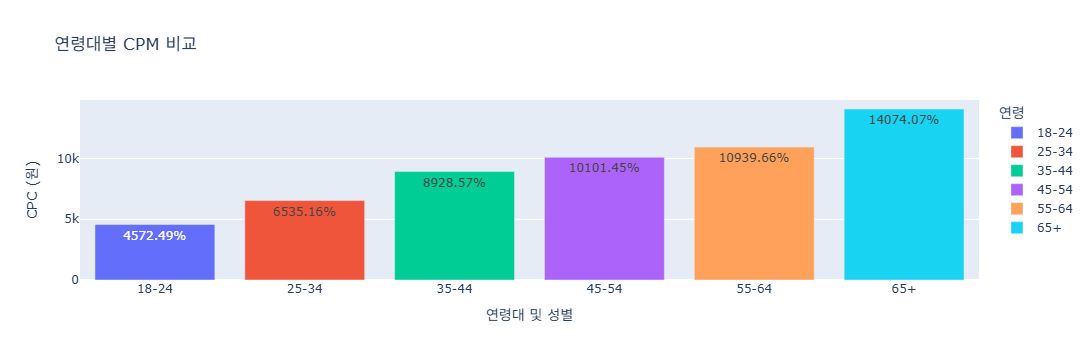

In [64]:
fig = px.bar(
    age_cost,
    x="연령",
    y="CPM",
    color="연령",
    text_auto=".0f",
    title="연령대별 CPM 비교" 
)

fig.update_traces(texttemplate="%{y:.2f}%")

fig.update_layout(
    xaxis_title="연령대 및 성별",
    yaxis_title="CPC (원)"
)

fig.show()

In [ ]:
# 2. 왜 4050, 65+는 높게 나왔을까? 가설 : 고 연령대 일수록, 선물하기 및 카카오톡의 관심이 높아서!

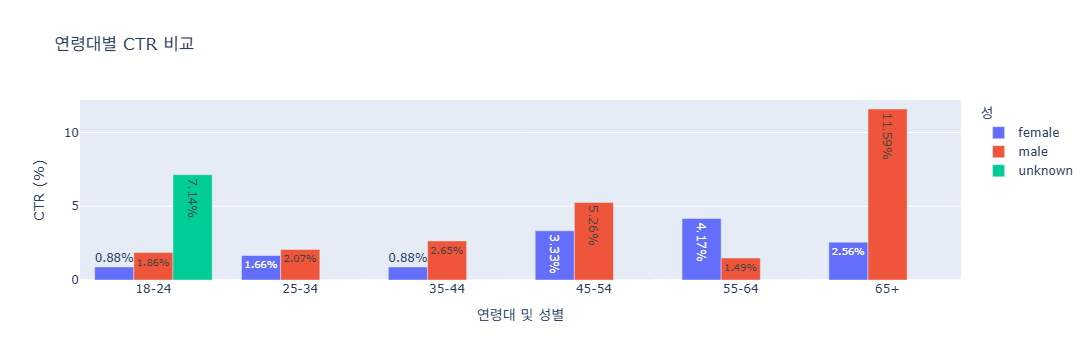

In [65]:
fig = px.bar(
    age_gender,
    x="연령",
    y="CTR",
    color="성",
    barmode="group",
    text_auto=".2f",
    title="연령대별 CTR 비교" 
)

fig.update_traces(texttemplate="%{y:.2f}%")

fig.update_layout(
    xaxis_title="연령대 및 성별",
    yaxis_title="CTR (%)"
)

fig.show()

In [66]:
senior = ads[ads["연령"].isin(["45-54", "65+"])].copy()

senior

,캠페인 이름,광고 세트 이름,광고 이름,연령,성,도달,노출,빈도,결과,지출 금액 (KRW),링크 클릭,클릭(전체),광고 유형,메세지 유형
13,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,65+,female,16,16,1.00,0.00,405,0.00,0,영상,혜택강조
14,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,65+,male,28,28,1.00,7.00,383,8.00,7,영상,혜택강조
16,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,65+,male,21,21,1.00,0.00,353,0.00,0,영상,감성자극
21,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,45-54,male,28,28,1.00,1.00,294,2.00,2,영상,감성자극
23,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_혜택강조,이미지_혜택강조,45-54,female,13,14,1.08,1.00,262,1.00,1,이미지,혜택강조
28,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,45-54,male,22,22,1.00,1.00,204,1.00,1,영상,혜택강조
29,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상_혜택강조,영상_혜택강조,45-54,female,20,21,1.05,0.00,177,0.00,0,영상,혜택강조
30,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,65+,female,11,11,1.00,1.00,176,1.00,1,영상,감성자극
38,핑퐁 위시리스트 - 이미지,핑퐁위시리스트_이미지_감성자극,이미지_감성자극,45-54,male,15,15,1.00,0.00,117,0.00,0,이미지,감성자극
39,핑퐁 위시리스트 - 영상,핑퐁위시리스트_영상 _감성자극,영상_감성자극,45-54,female,14,14,1.00,0.00,111,0.00,0,영상,감성자극


In [67]:
segment_senior = senior.groupby(["연령", "성", "광고 유형", "메세지 유형"], as_index=False)[
    ["노출", "링크 클릭", "결과", "지출 금액 (KRW)"]
].sum()

segment_senior["CTR"] = segment_senior["링크 클릭"] / segment_senior["노출"] * 100
segment_senior["CPC"] = segment_senior["지출 금액 (KRW)"] / segment_senior["링크 클릭"].replace(0, np.nan)

segment_senior

,연령,성,광고 유형,메세지 유형,노출,링크 클릭,결과,지출 금액 (KRW),CTR,CPC
0,45-54,female,영상,감성자극,14,0.00,0.00,111,0.00,NaN
1,45-54,female,영상,혜택강조,21,0.00,0.00,177,0.00,NaN
2,45-54,female,이미지,감성자극,11,1.00,0.00,70,9.09,70.00
3,45-54,female,이미지,혜택강조,14,1.00,1.00,262,7.14,262.00
4,45-54,male,영상,감성자극,28,2.00,1.00,294,7.14,147.00
5,45-54,male,영상,혜택강조,22,1.00,1.00,204,4.55,204.00
6,45-54,male,이미지,감성자극,15,0.00,0.00,117,0.00,NaN
7,45-54,male,이미지,혜택강조,11,1.00,1.00,98,9.09,98.00
8,45-54,unknown,영상,감성자극,1,0.00,0.00,52,0.00,NaN
9,45-54,unknown,영상,혜택강조,1,0.00,0.00,9,0.00,NaN


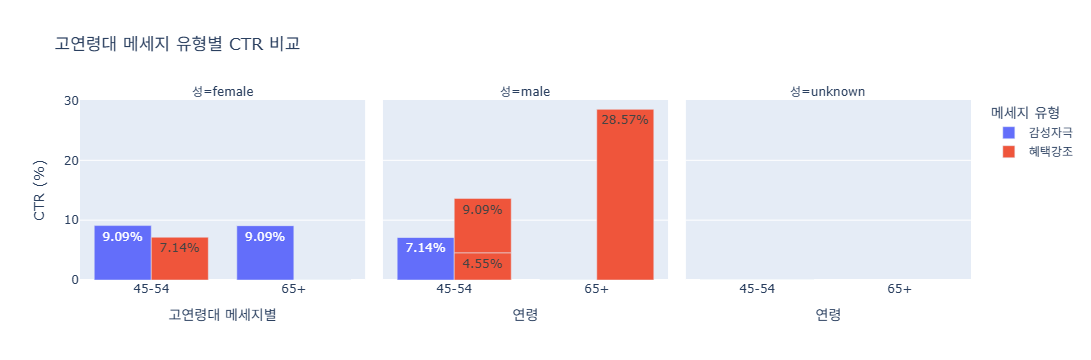

In [68]:
fig = px.bar(
    segment_senior,
    x="연령",
    y="CTR",
    color="메세지 유형",
    barmode="group",
    facet_col="성",
    text_auto=".2f",
    title="고연령대 메세지 유형별 CTR 비교" 
)

fig.update_traces(texttemplate="%{y:.2f}%")

fig.update_layout(
    xaxis_title="고연령대 메세지별",
    yaxis_title="CTR (%)"
)

fig.show()

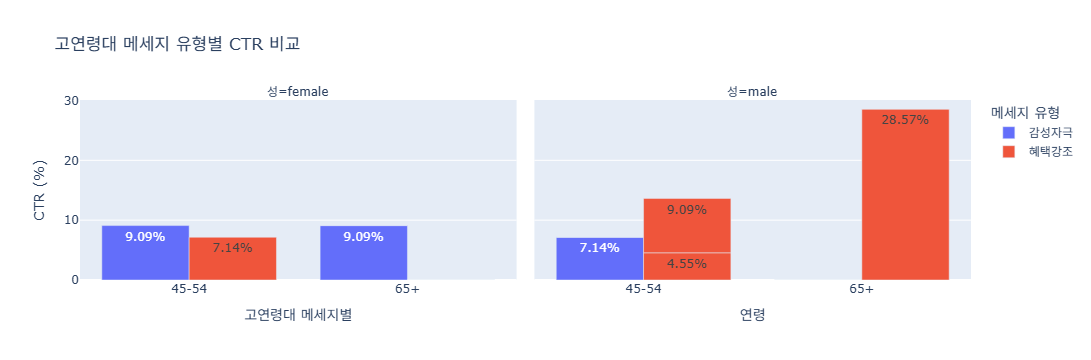

In [69]:
fig = px.bar(
    segment_senior[segment_senior["성"] != "unknown"],
    x="연령",
    y="CTR",
    color="메세지 유형",
    barmode="group",
    facet_col="성",
    text_auto=".2f",
    title="고연령대 메세지 유형별 CTR 비교" 
)

fig.update_traces(texttemplate="%{y:.2f}%")

fig.update_layout(
    xaxis_title="고연령대 메세지별",
    yaxis_title="CTR (%)"
)

fig.show()